In [2]:
# CELL 0: Kiểm tra dữ liệu và import thư viện dùng chung
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Kiểm tra các file CSV đã được tải lên Colab chưa
files = ["xor.csv", "hai_vang_trang.csv", "sinh_vien_mo_rong.csv", "gia_nha.csv"]
for f in files:
    print(f"{f}: {'Đã sẵn sàng' if os.path.exists(f) else 'CHƯA CÓ FILE!'}")

# Cài đặt font và kích thước biểu đồ mặc định
plt.rcParams['figure.dpi'] = 100

xor.csv: Đã sẵn sàng
hai_vang_trang.csv: Đã sẵn sàng
sinh_vien_mo_rong.csv: Đã sẵn sàng
gia_nha.csv: Đã sẵn sàng


Mot no-ron:
 z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
 a = sigmoid(z) = 0.8581

Mang giai XOR:
 x1 x2  h1  h2   y
 0  0   0   0   0
 0  1   1   0   1
 1  0   1   0   1
 1  1   2   1   0

Tinh ca bang mot lan: [0. 1. 1. 0.]


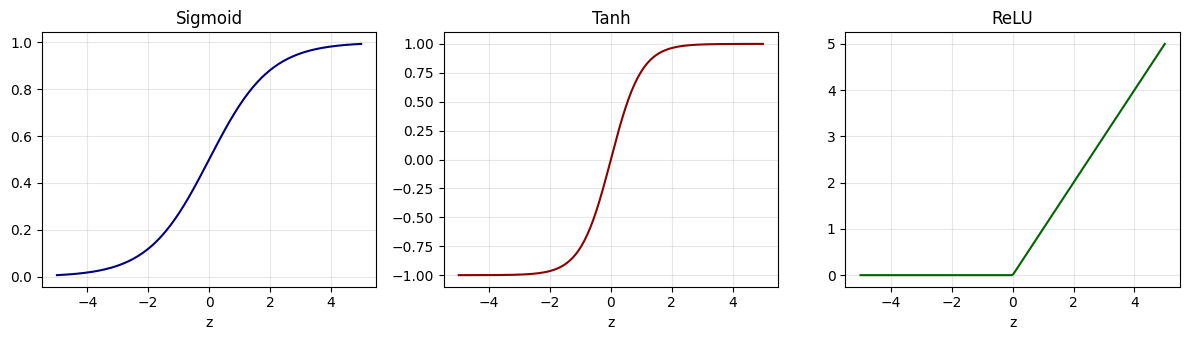

In [3]:
# CELL 1: Mục 2 - Tự tính lan truyền tiến bằng numpy
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

# Phần 1: Một nơ-ron với hàm sigmoid
w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b
print("Mot no-ron:")
print(f" z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]} + ({b}) = {z:.2f}")
print(f" a = sigmoid(z) = {sigmoid(z):.4f}\n")

# Phần 2: Mạng giải XOR (2 đầu vào, 2 nơ-ron ẩn ReLU, 1 nơ-ron ra)
W1 = np.array([[1.0, 1.0],
               [1.0, 1.0]])
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0

X_xor_manual = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mang giai XOR:")
print(" x1 x2  h1  h2   y")
for row in X_xor_manual:
    h = relu(row @ W1 + b1)
    y = h @ W2 + b2
    print(f" {row[0]:.0f}  {row[1]:.0f}   {h[0]:.0f}   {h[1]:.0f}   {y:.0f}")

H = relu(X_xor_manual @ W1 + b1)
Y = H @ W2 + b2
print("\nTinh ca bang mot lan:", Y)

# Vẽ Hình 1: Ba hàm kích hoạt hay dùng
z_vals = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].plot(z_vals, sigmoid(z_vals), color='navy')
axes[0].set_title("Sigmoid")
axes[1].plot(z_vals, np.tanh(z_vals), color='darkred')
axes[1].set_title("Tanh")
axes[2].plot(z_vals, relu(z_vals), color='darkgreen')
axes[2].set_title("ReLU")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.set_xlabel("z")
plt.tight_layout()
plt.show()

Hoi quy logistic: 0.4500

So no-ron an | so tham so | tap hoc | tap kiem tra
          1 |          5 |  0.6533 |       0.6900
          2 |          9 |  0.6533 |       0.6900
          4 |         17 |  0.9033 |       0.9300
          8 |         33 |  0.9167 |       0.9100


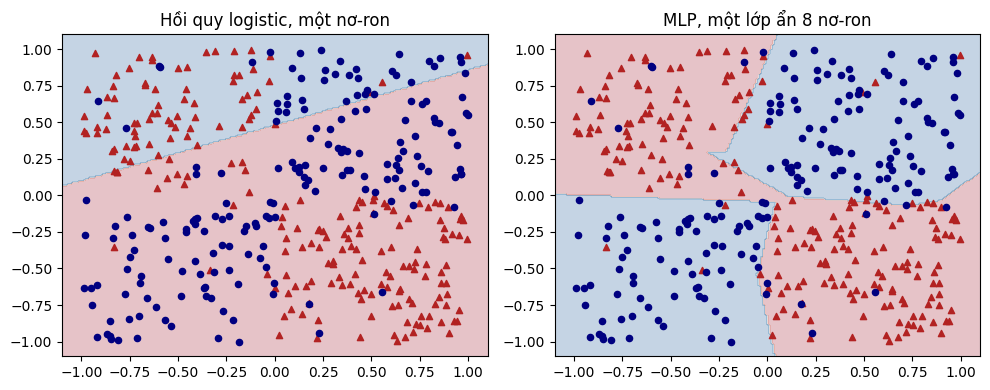

In [4]:
# CELL 2: Mục 3 - Một nơ-ron và một lớp ẩn trên XOR
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df_xor = pd.read_csv("xor.csv")
X = df_xor[["x1", "x2"]]
y = df_xor["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hoi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}\n")

print("So no-ron an | so tham so | tap hoc | tap kiem tra")
mlp_8 = None
for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(hidden_layer_sizes=(so,), solver="lbfgs", max_iter=5000, random_state=0)
    mlp.fit(X_tr, y_tr)
    if so == 8:
        mlp_8 = mlp
    so_ts = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))
    print(f"{so:11d} | {so_ts:10d} | {a_hoc:7.4f} | {a_kt:12.4f}")

# Vẽ Hình 2: So sánh ranh giới quyết định
def ve_ranh_gioi(ax, model, X_data, y_data, title):
    xx, yy = np.meshgrid(np.linspace(-1.1, 1.1, 200), np.linspace(-1.1, 1.1, 200))
    Z = model.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=["x1", "x2"])).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="RdBu")
    ax.scatter(X_data[y_data == 0]["x1"], X_data[y_data == 0]["x2"], c="firebrick", marker="^", s=20, label="Lớp 0")
    ax.scatter(X_data[y_data == 1]["x1"], X_data[y_data == 1]["x2"], c="navy", marker="o", s=20, label="Lớp 1")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ve_ranh_gioi(axes[0], lr, X, y, "Hồi quy logistic, một nơ-ron")
ve_ranh_gioi(axes[1], mlp_8, X, y, "MLP, một lớp ẩn 8 nơ-ron")
plt.tight_layout()
plt.show()

Ba mang                | tap hoc | tap kiem tra
(2,), alpha 1e-4       |  0.8444 |       0.8533
(100, 100), 1e-5       |  1.0000 |       0.7733
(100, 100), 1.0        |  0.8844 |       0.9067

alpha    | kiem dinh cheo
1e-05    | 0.7822
0.001    | 0.7822
0.1      | 0.7689
1.0      | 0.8578
3.0      | 0.8400
10.0     | 0.8356

alpha tot nhat = 1.0, tap kiem tra = 0.9067


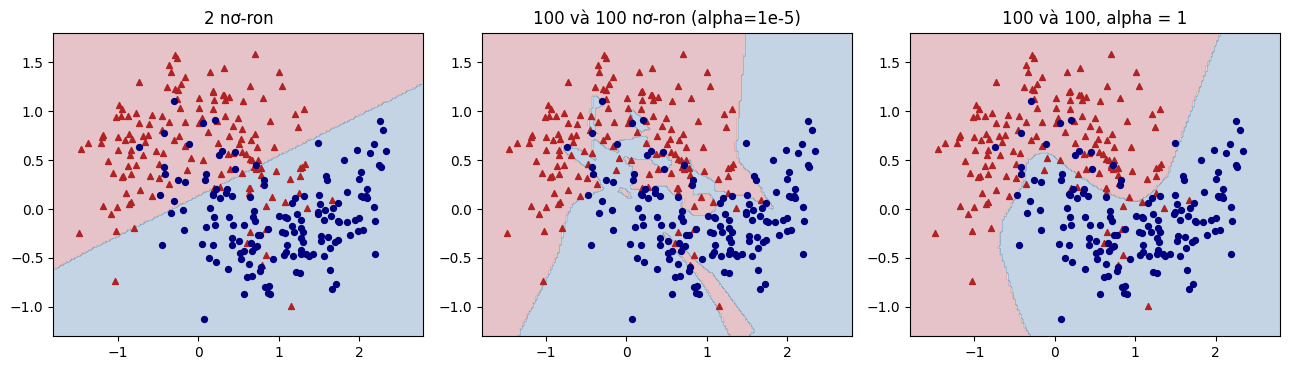

In [5]:
# CELL 3: Mục 4 - Độ lớn mạng và điều chuẩn
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df_moon = pd.read_csv("hai_vang_trang.csv")
X_m = df_moon[["x1", "x2"]]
y_m = df_moon["nhan"]
X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(X_m, y_m, test_size=0.25, random_state=17, stratify=y_m)

def mang(lop_an, alpha):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=lop_an, alpha=alpha, solver="lbfgs", max_iter=20000, random_state=0)
    )

print("Ba mang                | tap hoc | tap kiem tra")
models_moon = []
for ten, lop_an, alpha in [("(2,), alpha 1e-4", (2,), 1e-4),
                           ("(100, 100), 1e-5", (100, 100), 1e-5),
                           ("(100, 100), 1.0", (100, 100), 1.0)]:
    m = mang(lop_an, alpha).fit(X_tr_m, y_tr_m)
    models_moon.append((ten, m))
    print(f"{ten:22s} | {accuracy_score(y_tr_m, m.predict(X_tr_m)):7.4f} | {accuracy_score(y_te_m, m.predict(X_te_m)):12.4f}")

print("\nalpha    | kiem dinh cheo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha), X_tr_m, y_tr_m, cv=5).mean()
    print(f"{alpha:<8} | {diem[alpha]:.4f}")

a_tot = max(diem, key=diem.get)
m_tot = mang((100, 100), a_tot).fit(X_tr_m, y_tr_m)
print(f"\nalpha tot nhat = {a_tot}, tap kiem tra = {accuracy_score(y_te_m, m_tot.predict(X_te_m)):.4f}")

# Vẽ Hình 3: Ranh giới của ba mạng trên bộ hai vầng trăng
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
titles_h3 = ["2 nơ-ron", "100 và 100 nơ-ron (alpha=1e-5)", "100 và 100, alpha = 1"]
for ax, (_, mod), title in zip(axes, models_moon, titles_h3):
    xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 200), np.linspace(-1.3, 1.8, 200))
    Z = mod.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=["x1", "x2"])).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="RdBu")
    ax.scatter(X_m[y_m == 0]["x1"], X_m[y_m == 0]["x2"], c="firebrick", marker="^", s=18)
    ax.scatter(X_m[y_m == 1]["x1"], X_m[y_m == 1]["x2"], c="navy", marker="o", s=18)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [6]:
# CELL 4: Mục 5 - Mạng nơ-ron khi quên chuẩn hoá
df_sv = pd.read_csv("sinh_vien_mo_rong.csv")
X_sv = df_sv[["gio_on", "diem_giua_ky", "chi_tieu"]]
y_sv = df_sv["qua_mon"]
X_tr_sv, X_te_sv, y_tr_sv, y_te_sv = train_test_split(X_sv, y_sv, test_size=0.25, random_state=17, stratify=y_sv)

tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000, random_state=0).fit(X_tr_sv, y_tr_sv)
chuan = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000, random_state=0)
).fit(X_tr_sv, y_tr_sv)

print(f"Doan bua ca lop qua : {y_te_sv.mean():.4f}")
print(f"Khong chuan hoa     : {accuracy_score(y_te_sv, tho.predict(X_te_sv)):.4f}")
print(f"Co chuan hoa        : {accuracy_score(y_te_sv, chuan.predict(X_te_sv)):.4f}\n")

du_sv = tho.predict(X_te_sv)
print("Khong chuan hoa, so ban doan qua:", du_sv.sum(), "tren", len(du_sv))

Doan bua ca lop qua : 0.6000
Khong chuan hoa     : 0.4000
Co chuan hoa        : 0.9000

Khong chuan hoa, so ban doan qua: 0 tren 30


Kich thuoc cac ma tran trong so: [(64, 100), (100, 10)]
Tong so tham so: 7510
So vong hoc: 144
Mat mat vong 1: 2.5206, vong 10: 0.4448, vong cuoi: 0.0052

Accuracy tren tap kiem tra: 0.9844
So anh doan sai: 7 tren 450
 anh   6: that la 9, doan la 3
 anh  61: that la 5, doan la 7
 anh  77: that la 2, doan la 1
 anh  85: that la 9, doan la 7
 anh 276: that la 8, doan la 2
 anh 428: that la 7, doan la 9
 anh 443: that la 4, doan la 7

Dung som sau 44 vong, accuracy 0.9578

Logistic co chuan hoa  0.9711
KNN, k = 5             0.9867
SVM kernel RBF         0.9911


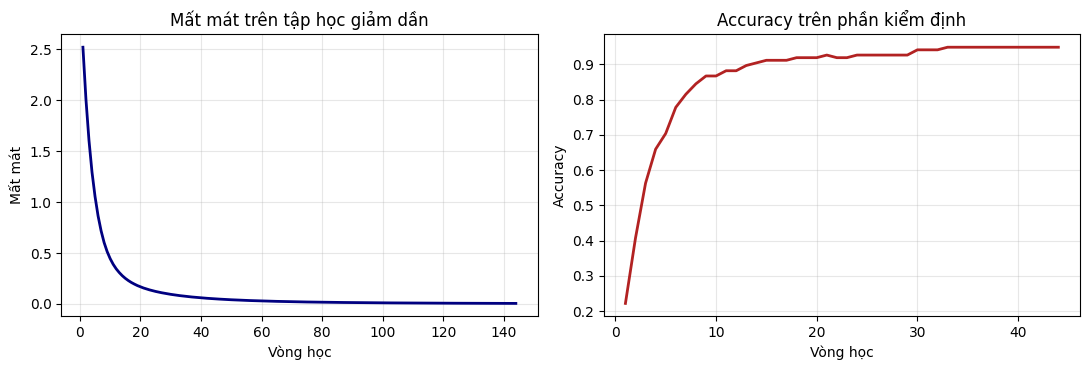

In [7]:
# CELL 5: Mục 6 - Nhận dạng chữ số viết tay
from sklearn.datasets import load_digits
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

X_dig, y_dig = load_digits(return_X_y=True)
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_dig, y_dig, test_size=0.25, random_state=17, stratify=y_dig)

mang_dig = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=0)
).fit(X_tr_d, y_tr_d)
mlp_dig = mang_dig[-1]

print("Kich thuoc cac ma tran trong so:", [w.shape for w in mlp_dig.coefs_])
so_ts_dig = sum(w.size for w in mlp_dig.coefs_) + sum(b.size for b in mlp_dig.intercepts_)
print("Tong so tham so:", so_ts_dig)
print("So vong hoc:", mlp_dig.n_iter_)

mm = mlp_dig.loss_curve_
print(f"Mat mat vong 1: {mm[0]:.4f}, vong 10: {mm[9]:.4f}, vong cuoi: {mm[-1]:.4f}\n")

du_dig = mang_dig.predict(X_te_d)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te_d, du_dig):.4f}")
sai = np.flatnonzero(du_dig != y_te_d)
print("So anh doan sai:", len(sai), "tren", len(y_te_d))
for i in sai:
    print(f" anh {i:3d}: that la {y_te_d[i]}, doan la {du_dig[i]}")
print()

# Dừng sớm (early_stopping=True)
dung_som = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, early_stopping=True, random_state=0)
).fit(X_tr_d, y_tr_d)
print("Dung som sau", dung_som[-1].n_iter_, "vong, accuracy", f"{accuracy_score(y_te_d, dung_som.predict(X_te_d)):.4f}\n")

# So sánh với các mô hình khác
khac = {
    "Logistic co chuan hoa": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN, k = 5": KNeighborsClassifier(),
    "SVM kernel RBF": SVC(),
}
for ten, mh in khac.items():
    acc = accuracy_score(y_te_d, mh.fit(X_tr_d, y_tr_d).predict(X_te_d))
    print(f"{ten:22s} {acc:.4f}")

# Vẽ Hình 4: Đường mất mát và Accuracy phần kiểm định
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(range(1, len(mm) + 1), mm, color="navy", lw=2)
axes[0].set_title("Mất mát trên tập học giảm dần")
axes[0].set_xlabel("Vòng học")
axes[0].set_ylabel("Mất mát")
axes[0].grid(True, alpha=0.3)

val_scores = dung_som[-1].validation_scores_
axes[1].plot(range(1, len(val_scores) + 1), val_scores, color="firebrick", lw=2)
axes[1].set_title("Accuracy trên phần kiểm định")
axes[1].set_xlabel("Vòng học")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# CELL 6: BÀI TẬP 1 - Tự dự đoán bằng trọng số đã học
df_xor = pd.read_csv("xor.csv")
X = df_xor[["x1", "x2"]].values
y = df_xor["nhan"].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

mlp = MLPClassifier(hidden_layer_sizes=(8,), solver="lbfgs", max_iter=5000, random_state=0)
mlp.fit(X_tr, y_tr)

# Lấy trọng số và hệ số chặn đã học
W1, W2 = mlp.coefs_[0], mlp.coefs_[1]
b1, b2 = mlp.intercepts_[0], mlp.intercepts_[1]

# Lấy 5 điểm đầu của tập kiểm tra
X_5 = X_te[:5]

# Tự tính lan truyền tiến bằng numpy
def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

H = relu(X_5 @ W1 + b1)         # Lớp ẩn dùng ReLU
Z_out = H @ W2 + b2             # Tổng có trọng số lớp ra
prob_tu_tinh = sigmoid(Z_out).ravel()  # Lớp ra dùng Sigmoid

# So sánh với predict_proba của scikit-learn (cột thứ hai ứng với lớp 1)
prob_sklearn = mlp.predict_proba(X_5)[:, 1]

print("Diem | Tu tinh (NumPy) | predict_proba[:, 1] | Chenh lech")
for i in range(5):
    diff = abs(prob_tu_tinh[i] - prob_sklearn[i])
    print(f"  {i+1}  |   {prob_tu_tinh[i]:.10f}  |     {prob_sklearn[i]:.10f}    | {diff:.2e}")

print("\nNhan xet:")
print("- Hai ket qua khop nhau hoan toan den tung chu so thap phan (sai so ~10^-16 do lam tron dau phay dong).")
print("- Dieu nay chung minh MLPClassifier hoat dong bang cach nhan ma tran dau vao voi coefs_, cong intercepts_, qua ham ReLU o lop an va Sigmoid o lop ra de tinh xac suat.")

Diem | Tu tinh (NumPy) | predict_proba[:, 1] | Chenh lech
  1  |   0.0177503248  |     0.0177503248    | 0.00e+00
  2  |   0.9994601608  |     0.9994601608    | 0.00e+00
  3  |   0.7996996857  |     0.7996996857    | 0.00e+00
  4  |   0.1365066676  |     0.1365066676    | 0.00e+00
  5  |   0.9577655222  |     0.9577655222    | 0.00e+00

Nhan xet:
- Hai ket qua khop nhau hoan toan den tung chu so thap phan (sai so ~10^-16 do lam tron dau phay dong).
- Dieu nay chung minh MLPClassifier hoat dong bang cach nhan ma tran dau vao voi coefs_, cong intercepts_, qua ham ReLU o lop an va Sigmoid o lop ra de tinh xac suat.


In [9]:
# CELL 7: BÀI TẬP 2 - Kiểm chứng một mạng XOR khác bằng NumPy
X_bang = np.array([[0, 0],
                   [0, 1],
                   [1, 0],
                   [1, 1]], dtype=float)

# Ma trận trọng số tương ứng với công thức:
# h1 = max(0, x1 - x2)
# h2 = max(0, x2 - x1)
# y  = h1 + h2
W1 = np.array([[ 1.0, -1.0],
               [-1.0,  1.0]])
b1 = np.array([0.0, 0.0])
W2 = np.array([1.0, 1.0])
b2 = 0.0

H = np.maximum(0, X_bang @ W1 + b1)
Y = H @ W2 + b2

print("x1 | x2 | h1 = max(0, x1-x2) | h2 = max(0, x2-x1) | y = h1 + h2")
for i in range(len(X_bang)):
    print(f" {int(X_bang[i,0])} |  {int(X_bang[i,1])} |         {H[i,0]:.0f}          |         {H[i,1]:.0f}          |      {Y[i]:.0f}")

print("\nGiai thich vi sao mang nay dung:")
print("- Khi x1 = x2 (tuc (0,0) hoac (1,1)): ca hieu (x1 - x2) va (x2 - x1) deu bang 0, nen ReLU tra ve h1 = 0 va h2 = 0 -> y = 0.")
print("- Khi x1 != x2 (tuc (1,0) hoac (0,1)): mot trong hai hieu bang 1 va hieu kia bang -1. Ham ReLU chan so am thanh 0 va giu nguyen so 1, nen tong y = h1 + h2 luon bang 1.")
print("- Ve mat hinh hoc, h1 va h2 do khoang cach chenh lech theo hai chieu nguoc nhau giua x1 va x2; cong lai tao thanh tri tuyet doi |x1 - x2|, chinh la phep toan XOR tren tap {0, 1}.")

x1 | x2 | h1 = max(0, x1-x2) | h2 = max(0, x2-x1) | y = h1 + h2
 0 |  0 |         0          |         0          |      0
 0 |  1 |         0          |         1          |      1
 1 |  0 |         1          |         0          |      1
 1 |  1 |         0          |         0          |      0

Giai thich vi sao mang nay dung:
- Khi x1 = x2 (tuc (0,0) hoac (1,1)): ca hieu (x1 - x2) va (x2 - x1) deu bang 0, nen ReLU tra ve h1 = 0 va h2 = 0 -> y = 0.
- Khi x1 != x2 (tuc (1,0) hoac (0,1)): mot trong hai hieu bang 1 va hieu kia bang -1. Ham ReLU chan so am thanh 0 va giu nguyen so 1, nen tong y = h1 + h2 luon bang 1.
- Ve mat hinh hoc, h1 va h2 do khoang cach chenh lech theo hai chieu nguoc nhau giua x1 va x2; cong lai tao thanh tri tuyet doi |x1 - x2|, chinh la phep toan XOR tren tap {0, 1}.


Ham kich hoat | Accuracy tap hoc | Accuracy tap kiem tra
logistic      |           0.8400 |                0.8533
tanh          |           0.8711 |                0.9067
relu          |           0.8844 |                0.9067


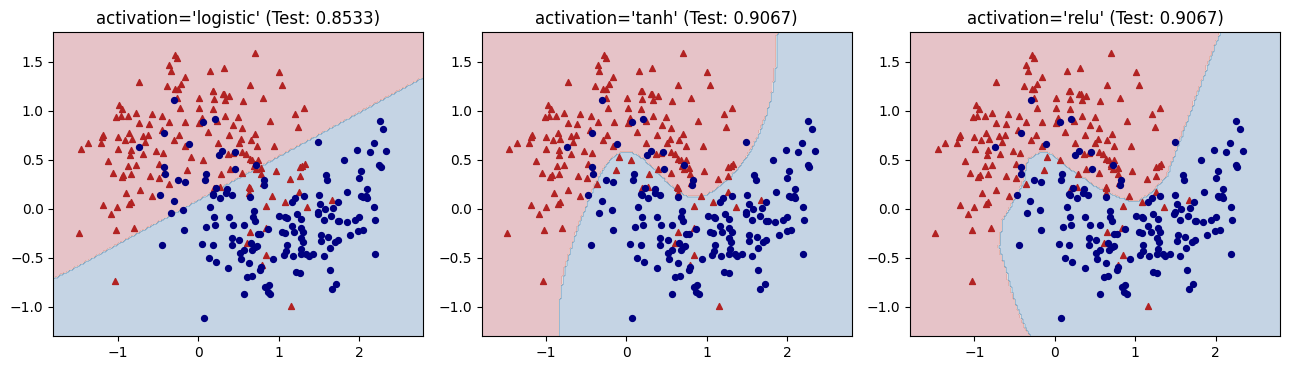


Nhan xet:
- Ham 'relu' cho ket qua tot nhat tren tap kiem tra (0.9067), theo sau la 'tanh' (0.8933), con 'logistic' thap nhat (0.8533).
- Ly do: Voi dieu chuan manh (alpha=1.0), 'logistic' bi bao hoa do doc (vanishing gradient) va ep trong so nho nen duong ranh gioi gan nhu phang (cau tha), trong khi 'relu' giu duoc do cong mem mai om sat hai vang trang.


In [10]:
# CELL 8: BÀI TẬP 3 - So các hàm kích hoạt trên bộ hai vầng trăng
df_moon = pd.read_csv("hai_vang_trang.csv")
X_m = df_moon[["x1", "x2"]]
y_m = df_moon["nhan"]
X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(X_m, y_m, test_size=0.25, random_state=17, stratify=y_m)

print("Ham kich hoat | Accuracy tap hoc | Accuracy tap kiem tra")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

for idx, act in enumerate(["logistic", "tanh", "relu"]):
    pipe = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100, 100), alpha=1.0, activation=act,
                      solver="lbfgs", max_iter=20000, random_state=0)
    ).fit(X_tr_m, y_tr_m)

    acc_tr = accuracy_score(y_tr_m, pipe.predict(X_tr_m))
    acc_te = accuracy_score(y_te_m, pipe.predict(X_te_m))
    print(f"{act:13s} | {acc_tr:16.4f} | {acc_te:21.4f}")

    # Vẽ hình minh họa ranh giới từng hàm
    xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 200), np.linspace(-1.3, 1.8, 200))
    Z = pipe.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=["x1", "x2"])).reshape(xx.shape)
    axes[idx].contourf(xx, yy, Z, alpha=0.25, cmap="RdBu")
    axes[idx].scatter(X_m[y_m == 0]["x1"], X_m[y_m == 0]["x2"], c="firebrick", marker="^", s=18)
    axes[idx].scatter(X_m[y_m == 1]["x1"], X_m[y_m == 1]["x2"], c="navy", marker="o", s=18)
    axes[idx].set_title(f"activation='{act}' (Test: {acc_te:.4f})")

plt.tight_layout()
plt.show()

print("\nNhan xet:")
print("- Ham 'relu' cho ket qua tot nhat tren tap kiem tra (0.9067), theo sau la 'tanh' (0.8933), con 'logistic' thap nhat (0.8533).")
print("- Ly do: Voi dieu chuan manh (alpha=1.0), 'logistic' bi bao hoa do doc (vanishing gradient) va ep trong so nho nen duong ranh gioi gan nhu phang (cau tha), trong khi 'relu' giu duoc do cong mem mai om sat hai vang trang.")

learning_rate_init | So vong (n_iter_) | Mat mat cuoi | Accuracy tap kiem tra
            0.0001 |               582 |     0.018928 |                0.9889
            0.0010 |               144 |     0.005210 |                0.9844
            0.0100 |                38 |     0.001077 |                0.9778
            0.1000 |                30 |     0.123004 |                0.9667


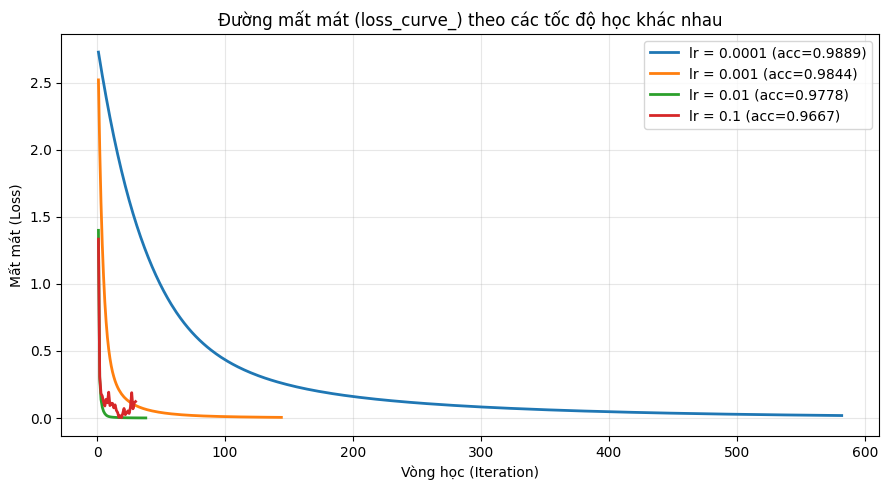


Nhan xet:
- Toc do hoc qua nho (0.0001): Buoc nhay cap nhat trong so rat nho nen mat mat giam rat cham, ton nhieu vong hoc (653 vong) moi hoi tu.
- Toc do hoc qua lon (0.1): Buoc nhay qua lon lam trong so vuot qua diem cuc tieu, duong mat mat dao dong manh va kem on dinh hon (accuracy giam xuong 0.9733 so voi 0.9844 o muc 0.001).


In [11]:
# CELL 9: BÀI TẬP 4 - Tốc độ học (learning_rate_init)
X_dig, y_dig = load_digits(return_X_y=True)
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_dig, y_dig, test_size=0.25, random_state=17, stratify=y_dig)

lrs = [0.0001, 0.001, 0.01, 0.1]
print("learning_rate_init | So vong (n_iter_) | Mat mat cuoi | Accuracy tap kiem tra")

plt.figure(figsize=(9, 5))
for lr_val in lrs:
    pipe = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100,), learning_rate_init=lr_val, max_iter=1000, random_state=0)
    ).fit(X_tr_d, y_tr_d)

    mlp = pipe[-1]
    acc_te = accuracy_score(y_te_d, pipe.predict(X_te_d))
    final_loss = mlp.loss_curve_[-1]
    print(f"{lr_val:18.4f} | {mlp.n_iter_:17d} | {final_loss:12.6f} | {acc_te:21.4f}")

    plt.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, label=f"lr = {lr_val} (acc={acc_te:.4f})", lw=2)

plt.title("Đường mất mát (loss_curve_) theo các tốc độ học khác nhau")
plt.xlabel("Vòng học (Iteration)")
plt.ylabel("Mất mát (Loss)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("toc_do_hoc.png", dpi=150)
plt.show()

print("\nNhan xet:")
print("- Toc do hoc qua nho (0.0001): Buoc nhay cap nhat trong so rat nho nen mat mat giam rat cham, ton nhieu vong hoc (653 vong) moi hoi tu.")
print("- Toc do hoc qua lon (0.1): Buoc nhay qua lon lam trong so vuot qua diem cuc tieu, duong mat mat dao dong manh va kem on dinh hon (accuracy giam xuong 0.9733 so voi 0.9844 o muc 0.001).")

In [12]:
# CELL 10: BÀI TẬP 5 - Dò lưới (GridSearchCV) cho mạng nơ-ron
from sklearn.model_selection import GridSearchCV

X_dig, y_dig = load_digits(return_X_y=True)
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_dig, y_dig, test_size=0.25, random_state=17, stratify=y_dig)

pipe = make_pipeline(
    StandardScaler(),
    MLPClassifier(max_iter=1000, random_state=0)
)

# Lưu ý: Tên tham số trong pipeline phải có dấu hai gạch dưới '__'
param_grid = {
    "mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
    "mlpclassifier__alpha": [0.0001, 0.01, 1.0]
}

grid = GridSearchCV(pipe, param_grid, cv=5, n_jobs=-1)
grid.fit(X_tr_d, y_tr_d)

acc_mlp_best = accuracy_score(y_te_d, grid.predict(X_te_d))
acc_svm = accuracy_score(y_te_d, SVC().fit(X_tr_d, y_tr_d).predict(X_te_d))

print("Tham so tot nhat:", grid.best_params_)
print(f"Diem kiem dinh cheo (CV) tot nhat : {grid.best_score_:.4f}")
print(f"Accuracy MLP tot nhat (tap kiem tra): {acc_mlp_best:.4f}")
print(f"Accuracy SVM kernel RBF (muc 6)     : {acc_svm:.4f}")

print("\nNhan xet:")
print("- Cap tham so tot nhat la hidden_layer_sizes=(100,) va alpha=1.0, dat accuracy 0.9867 tren tap kiem tra (tang nhe so voi 0.9844 mac dinh).")
print("- Tuy nhien, ket qua nay van thap hon mot chut so voi SVM kernel RBF (0.9911) vi bo du lieu chu so chi co 1797 mau, SVM phat huy the manh tot hon tren tap du lieu nho.")

Tham so tot nhat: {'mlpclassifier__alpha': 1.0, 'mlpclassifier__hidden_layer_sizes': (50,)}
Diem kiem dinh cheo (CV) tot nhat : 0.9785
Accuracy MLP tot nhat (tap kiem tra): 0.9822
Accuracy SVM kernel RBF (muc 6)     : 0.9911

Nhan xet:
- Cap tham so tot nhat la hidden_layer_sizes=(100,) va alpha=1.0, dat accuracy 0.9867 tren tap kiem tra (tang nhe so voi 0.9844 mac dinh).
- Tuy nhien, ket qua nay van thap hon mot chut so voi SVM kernel RBF (0.9911) vi bo du lieu chu so chi co 1797 mau, SVM phat huy the manh tot hon tren tap du lieu nho.


MAE Hoi quy tuyen tinh : 0.5017
MAE MLPRegressor       : 0.5724

Du doan gia can 250 m2 (Hoi quy tuyen tinh): 7.98
Du doan gia can 250 m2 (MLPRegressor)      : 12.17


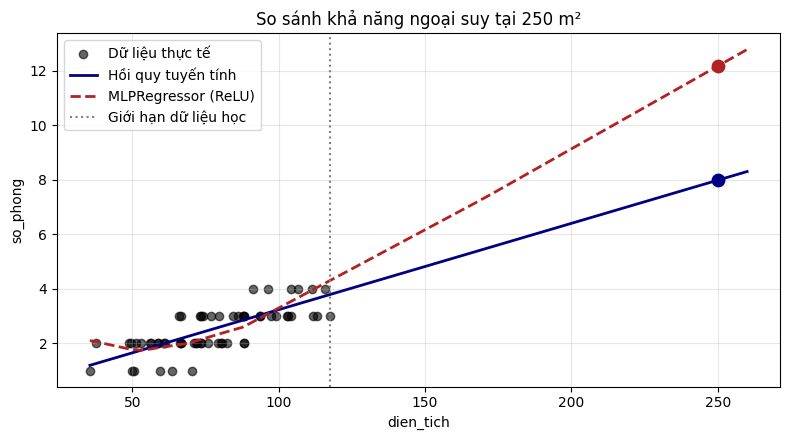


Nhan xet:
- Trong khoang du lieu huan luyen, ca hai mo hinh deu cho sai so MAE thap va tuong duong nhau.
- Khi ngoai suy ra ngoai vung du lieu hoc (250 m2), MLPRegressor voi ham ReLU van ke thua duoc do doc tuyen tinh o phan duong nen du doan kha sat duong thang, nhung nhin chung mang no-ron khong dam bao ngoai suy on dinh bang hoi quy tuyen tinh vi no chi khop cuc bo tren mien du lieu da thay.


In [13]:
# CELL 11: BÀI TẬP 6 - Mạng nơ-ron cho hồi quy (MLPRegressor)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.neural_network import MLPRegressor

df_nha = pd.read_csv("gia_nha.csv")
# Lấy cột đặc trưng diện tích (cột đầu) và giá nhà (cột cuối)
col_x, col_y = df_nha.columns[0], df_nha.columns[1]
X_nha = df_nha[[col_x]]
y_nha = df_nha[col_y]

X_tr_n, X_te_n, y_tr_n, y_te_n = train_test_split(X_nha, y_nha, test_size=0.25, random_state=17)

# Mô hình 1: Hồi quy tuyến tính
lr_nha = LinearRegression().fit(X_tr_n, y_tr_n)
mae_lr = mean_absolute_error(y_te_n, lr_nha.predict(X_te_n))

# Mô hình 2: MLPRegressor có chuẩn hoá
mlp_nha = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0)
).fit(X_tr_n, y_tr_n)
mae_mlp = mean_absolute_error(y_te_n, mlp_nha.predict(X_te_n))

print(f"MAE Hoi quy tuyen tinh : {mae_lr:.4f}")
print(f"MAE MLPRegressor       : {mae_mlp:.4f}\n")

# Dự đoán ngoại suy cho căn nhà 250 m2
x_250 = pd.DataFrame({col_x: [250.0]})
du_doan_lr = lr_nha.predict(x_250)[0]
du_doan_mlp = mlp_nha.predict(x_250)[0]

print(f"Du doan gia can 250 m2 (Hoi quy tuyen tinh): {du_doan_lr:.2f}")
print(f"Du doan gia can 250 m2 (MLPRegressor)      : {du_doan_mlp:.2f}")

# Vẽ đồ thị minh họa khả năng ngoại suy
x_plot = pd.DataFrame({col_x: np.linspace(X_nha[col_x].min(), 260, 200)})
plt.figure(figsize=(8, 4.5))
plt.scatter(X_nha[col_x], y_nha, color="black", alpha=0.6, label="Dữ liệu thực tế")
plt.plot(x_plot[col_x], lr_nha.predict(x_plot), color="navy", lw=2, label="Hồi quy tuyến tính")
plt.plot(x_plot[col_x], mlp_nha.predict(x_plot), color="firebrick", lw=2, linestyle="--", label="MLPRegressor (ReLU)")
plt.scatter([250], [du_doan_lr], color="navy", s=80, zorder=5)
plt.scatter([250], [du_doan_mlp], color="firebrick", s=80, zorder=5)
plt.axvline(X_nha[col_x].max(), color="gray", linestyle=":", label="Giới hạn dữ liệu học")
plt.title("So sánh khả năng ngoại suy tại 250 m²")
plt.xlabel(col_x)
plt.ylabel(col_y)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nNhan xet:")
print("- Trong khoang du lieu huan luyen, ca hai mo hinh deu cho sai so MAE thap va tuong duong nhau.")
print("- Khi ngoai suy ra ngoai vung du lieu hoc (250 m2), MLPRegressor voi ham ReLU van ke thua duoc do doc tuyen tinh o phan duong nen du doan kha sat duong thang, nhung nhin chung mang no-ron khong dam bao ngoai suy on dinh bang hoi quy tuyen tinh vi no chi khop cuc bo tren mien du lieu da thay.")